# Quantiva — descriptive statistical analysis

Keep observation grains separate: line amount, invoice value, known-customer spending,
and daily revenue. Statistics describe this finite observed sample. No significance
tests or causal claims are added. Outlier diagnostics do not change sales eligibility.


In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

from quantiva.analysis_report import collect_analysis
from quantiva.config import Settings
from quantiva.visualization import create_figures

if os.environ.get("QUANTIVA_KERNEL_EXECUTABLE"):
    assert (
        Path(sys.executable).resolve() == Path(os.environ["QUANTIVA_KERNEL_EXECUTABLE"]).resolve()
    )
root = Path.cwd()
while not ((root / "pyproject.toml").is_file() and (root / "src/quantiva").is_dir()):
    if root == root.parent:
        raise RuntimeError("Run within the Quantiva repository")
    root = root.parent
a = collect_analysis(Settings.from_environment())
s = a["summary"]
assert a["reconciliation"]["passed"].all()
figures = root / "reports" / "figures"
create_figures(a, figures)
print("Python", sys.version.split()[0], "— independent reconciliation passed")

Python 3.11.9 — independent reconciliation passed


## Location, spread, and shape

The mean averages all values and reacts to large orders. The median is the central
observation. Quartiles delimit the middle half; IQR = Q3 − Q1 is robust to tail size.
Percentiles locate the upper tail. Sample variance uses ddof=1 and has squared GBP
units; standard deviation is in GBP. Skewness describes asymmetry, not normality proof.


In [2]:
statistics = pd.DataFrame(s["statistics"]).T
display(statistics)
o = s["statistics"]["order_value_gbp"]
display(
    Markdown(
        f"Invoice mean **£{o['mean']:,.2f}** exceeds median **£{o['median']:,.2f}**; "
        f"skewness **{o['skewness']:.2f}** and IQR **£{o['iqr']:,.2f}** describe a long right "
        f"tail. "
        "Daily calendar statistics include dates without records, while the interior observed-day "
        "statistics provide a denominator sensitivity. Standard deviation is not a forecast "
        "interval."
    )
)

,count,mean,median,std,variance,q1,q3,p01,p95,p99,iqr,skewness,min,max
order_value_gbp,19960.0,533.171884,303.300,1780.412288,3.169868e+06,151.6950,493.4625,4.6800,1585.9210,4821.1654,341.7675,51.077769,0.380,168469.60
customer_spending_gbp,4338.0,2048.688081,668.570,8985.230220,8.073436e+07,306.4825,1660.5975,52.2000,5789.9995,19780.4878,1354.1150,19.339368,3.750,280206.02
line_amount_gbp,524878.0,20.275399,9.920,271.693566,7.381739e+04,3.9000,17.7000,0.5500,59.8000,183.6000,13.8000,504.232562,0.001,168469.60
daily_revenue_calendar_gbp,374.0,28454.841722,25919.560,23376.423816,5.464572e+08,12093.0750,39849.8100,0.0000,65745.1340,96921.3824,27756.7350,1.647947,0.000,200900.98
daily_revenue_observed_interior_gbp,303.0,34265.455558,29270.841,18829.436411,3.545477e+08,22216.7000,45201.4600,5707.0234,68391.8800,95801.1922,22984.7600,1.157301,3439.670,114237.40


Invoice mean **£533.17** exceeds median **£303.30**; skewness **51.08** and IQR **£341.77** describe a long right tail. Daily calendar statistics include dates without records, while the interior observed-day statistics provide a denominator sensitivity. Standard deviation is not a forecast interval.

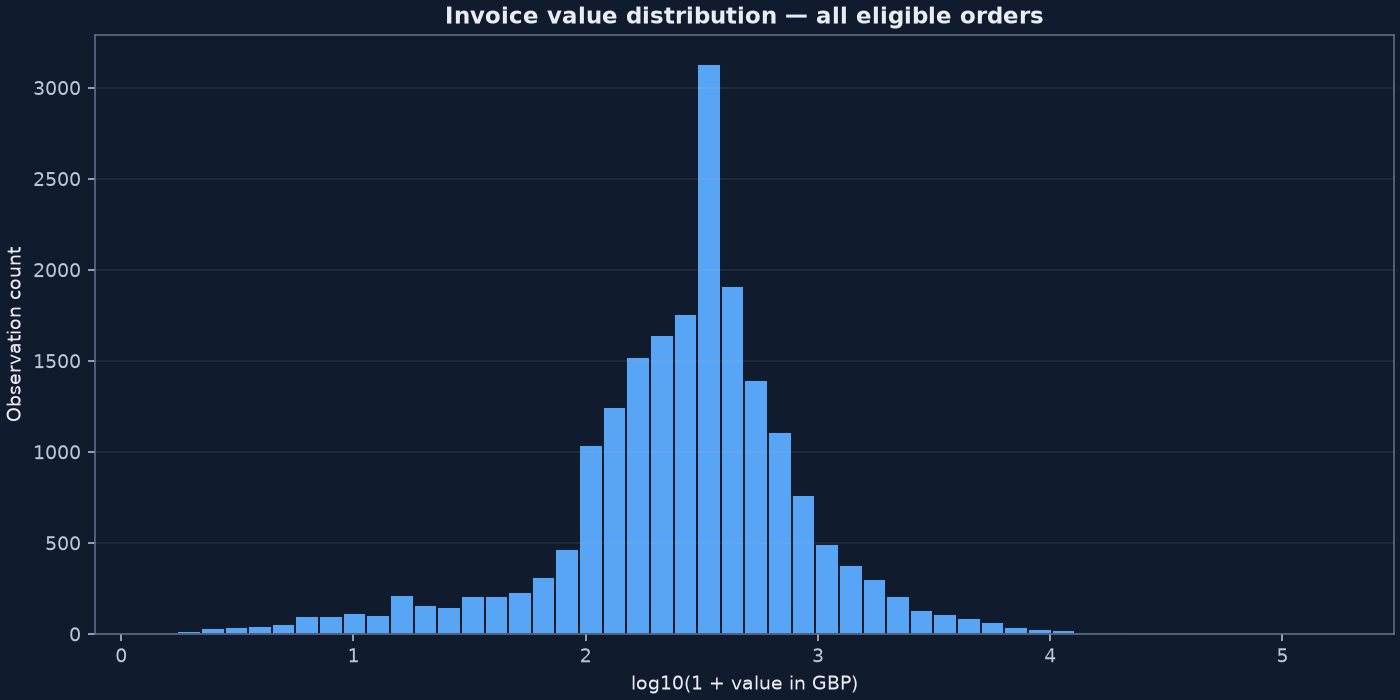

In [3]:
display(Image(filename=str(figures / "order_values.png")))

**Interpretation.** The log10(1 + GBP) transform changes the horizontal scale only. All eligible invoices remain in the histogram and all reported KPIs use original GBP values.

## Outlier influence without automatic deletion

In [4]:
display(pd.DataFrame([s["outliers"]]).T.rename(columns={0: "value"}))
display(a["orders"].nlargest(10, "revenue_gbp")[["revenue_gbp", "units", "lines"]])
display(
    Markdown(
        f"The mean at/below the 99th percentile is "
        f"**£{s['outliers']['mean_orders_at_or_below_p99_gbp']:,.2f}**, compared with full AOV "
        f"**£{s['kpis']['aov_gbp']:,.2f}**. Above-p99 invoices contribute "
        f"**{s['outliers']['top_one_percent_order_share_pct']:.2f}%** of gross revenue. "
        "This sensitivity demonstrates influence; it does not justify removing wholesale "
        "purchases. "
        "A Tukey fence flags unusual observations, not proven data errors."
    )
)

,value
tukey_upper_fence_gbp,1006.113750
above_tukey_fence_orders,1811.000000
mean_orders_at_or_below_p99_gbp,434.236839
top_one_percent_order_share_pct,19.372011
max_quantity,80995.000000
max_unit_price_gbp,13541.330000


,revenue_gbp,units,lines
19923,168469.60,80995,1
2116,77183.60,74215,1
16923,52940.94,14149,101
17579,50653.91,13956,99
8693,38970.00,60,1
13545,31698.16,12572,12
8899,22775.93,15049,138
15693,22206.00,1920,7
13537,22104.80,6760,12
11881,21880.44,12196,97


The mean at/below the 99th percentile is **£434.24**, compared with full AOV **£533.17**. Above-p99 invoices contribute **19.37%** of gross revenue. This sensitivity demonstrates influence; it does not justify removing wholesale purchases. A Tukey fence flags unusual observations, not proven data errors.

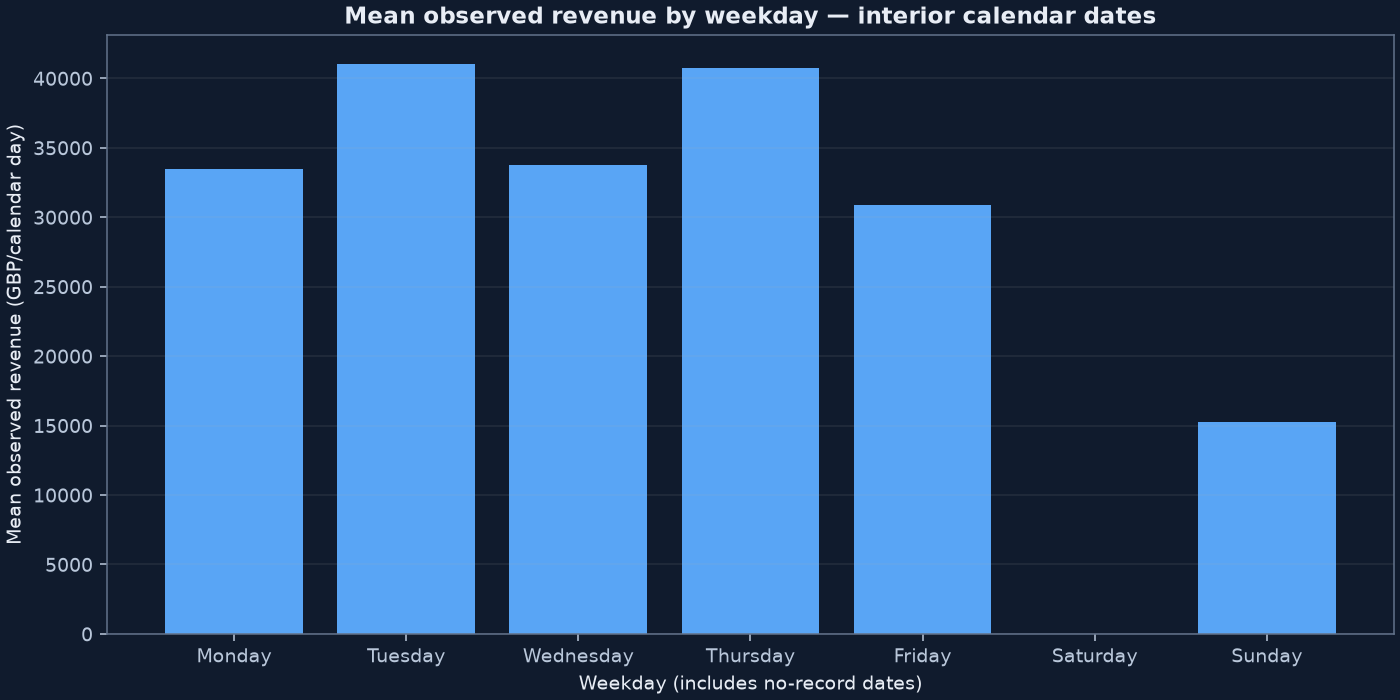

In [5]:
display(Image(filename=str(figures / "weekday_revenue.png")))

**Interpretation.** All interior calendar dates form the denominator, including no-record dates. Weekday averages can reflect trading schedules, customer mix, and missing capture; no causal weekday effect is inferred.

## Correlations at consistent observation grains

In [6]:
display(pd.DataFrame([s["correlations"]]).T.rename(columns={0: "correlation"}))
display(
    Markdown(
        "Pearson correlation measures linear association. Pearson on average ranks is "
        "Spearman rank correlation, which is less sensitive to the size of extremes. Invoice "
        "units/value "
        "and customer frequency/spending accumulate together mechanically; association is not "
        "causation. "
        "No line-level correlation is mixed with customer-level data."
    )
)

,correlation
invoice_units_value_pearson,0.882687
invoice_units_value_rank,0.838985
customer_frequency_spending_pearson,0.552780
customer_frequency_spending_rank,0.807185


Pearson correlation measures linear association. Pearson on average ranks is Spearman rank correlation, which is less sensitive to the size of extremes. Invoice units/value and customer frequency/spending accumulate together mechanically; association is not causation. No line-level correlation is mixed with customer-level data.

## Conclusions and limitations

Mean/median gaps, percentile concentration, and outlier sensitivity support using
robust summaries alongside totals. Anonymous customers limit customer-level inference.
The source is one retailer over roughly one year, with wholesale customers and a
partial final day. This is descriptive analysis; forecasting validation must establish
predictive usefulness separately in Phase 3. Missing dates remain an open modeling
decision rather than unqualified zero demand.
